<a href="https://colab.research.google.com/github/n1m1nd33p/Practical-ML/blob/main/Copy_of_Lab_KMeans_DBSCAN_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Lab Experiment 6****: K-Means and DBSCAN Clustering**

**Aim:** Load and preprocess an unsupervised-learning dataset, apply StandardScaler, perform K-Means and DBSCAN clustering, and visualize/compare both algorithms.

**Dataset:** `DBSCAN_KMeans_Dataset.csv` (synthetic two-feature dataset with 500 observations).  
**Features:** `Feature_1` and `Feature_2`. There is no target column because this is an unsupervised-learning task.

The two curved groups make this dataset useful for seeing how DBSCAN can identify non-spherical clusters, while K-Means partitions the data around cluster centroids.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
df = pd.read_csv("DBSCAN_KMeans_Dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (500, 2)


,Feature_1,Feature_2
0,0.830622,-0.432614
1,0.740349,0.825196
2,1.033435,-0.489607
3,-0.293316,0.964066
4,0.308208,1.093364


In [ ]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature_1  500 non-null    float64
 1   Feature_2  500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB

Missing values:
Feature_1    0
Feature_2    0
dtype: int64

Statistical summary:


,Feature_1,Feature_2
count,500.000000,500.000000
mean,0.506351,0.251878
std,0.871766,0.501909
min,-1.131984,-0.653358
25%,-0.036730,-0.209559
50%,0.473618,0.261045
75%,1.057580,0.695747
max,2.117060,1.164108


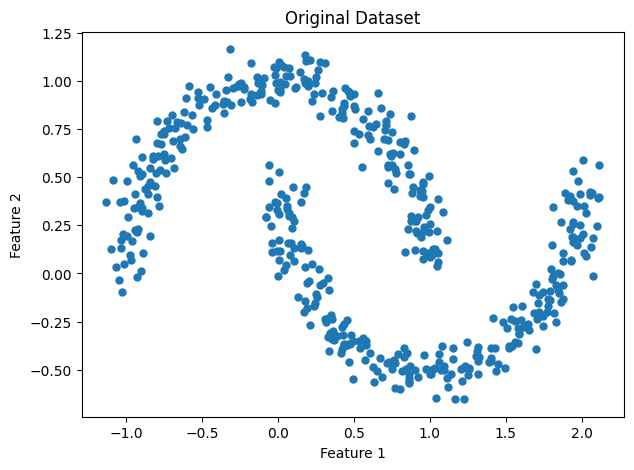

In [ ]:
X = df[["Feature_1", "Feature_2"]]

plt.figure(figsize=(7, 5))
plt.scatter(X["Feature_1"], X["Feature_2"], s=25)
plt.title("Original Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features standardized successfully!")


Features standardized successfully!


## Algorithm Comparison

- **K-Means:** Divides observations into a fixed number of clusters. Here, `n_clusters=2`.
- **DBSCAN:** Groups points based on density. It does not require the number of clusters in advance and marks outliers/noise with label `-1`.


In [ ]:
kmeans = KMeans(n_clusters=2, init="k-means++", random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")
print("Clusters found:", len(set(kmeans_labels)))


K-Means clustering completed!
Clusters found: 2


In [ ]:
dbscan = DBSCAN(eps=0.25, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print("DBSCAN clustering completed!")
print("Clusters found (excluding noise):", n_clusters_dbscan)
print("Noise points:", n_noise)


DBSCAN clustering completed!
Clusters found (excluding noise): 2
Noise points: 0


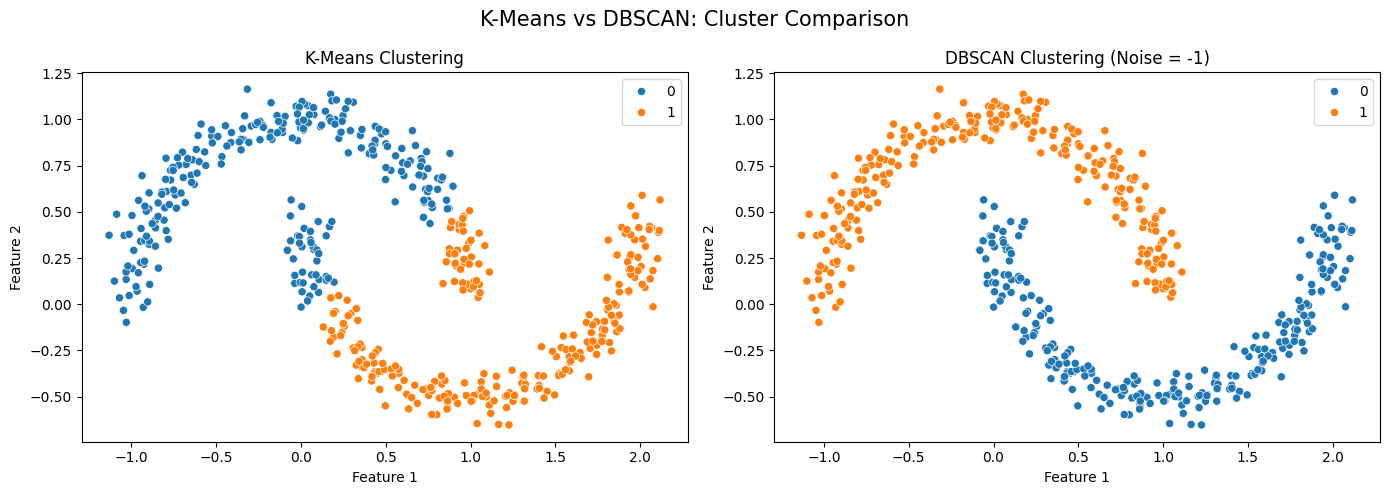

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    x=X["Feature_1"], y=X["Feature_2"],
    hue=kmeans_labels, palette="tab10",
    s=35, ax=axes[0], legend="full"
)
axes[0].set_title("K-Means Clustering")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

sns.scatterplot(
    x=X["Feature_1"], y=X["Feature_2"],
    hue=dbscan_labels, palette="tab10",
    s=35, ax=axes[1], legend="full"
)
axes[1].set_title("DBSCAN Clustering (Noise = -1)")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")

plt.suptitle("K-Means vs DBSCAN: Cluster Comparison", fontsize=15)
plt.tight_layout()
plt.show()


In [ ]:
kmeans_count = len(set(kmeans_labels))
dbscan_count = n_clusters_dbscan

comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN"],
    "Number_of_Clusters": [kmeans_count, dbscan_count],
    "Noise_Points": [0, n_noise]
})

display(comparison)


,Algorithm,Number_of_Clusters,Noise_Points
0,K-Means,2,0
1,DBSCAN,2,0


In [ ]:
kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
print("K-Means Silhouette Score:", round(kmeans_silhouette, 4))

dbscan_mask = dbscan_labels != -1
dbscan_valid_labels = dbscan_labels[dbscan_mask]

if len(set(dbscan_valid_labels)) >= 2:
    dbscan_silhouette = silhouette_score(
        X_scaled[dbscan_mask], dbscan_valid_labels
    )
    print("DBSCAN Silhouette Score (noise excluded):",
          round(dbscan_silhouette, 4))
else:
    print("DBSCAN silhouette score cannot be calculated: "
          "DBSCAN found fewer than 2 non-noise clusters.")


K-Means Silhouette Score: 0.4944
DBSCAN Silhouette Score (noise excluded): 0.3857
